In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [36]:
df = pd.read_csv('/content/OnlineRetail (3).csv',encoding='ISO-8859-1')

In [37]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [38]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


In [39]:
df.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


In [40]:
df.duplicated().sum()

np.int64(5268)

In [41]:
df=df.dropna(subset=['CustomerID'])

In [42]:
df.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,0
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,0
Country,0


In [43]:
df = df[(df['Quantity']>0)&(df['UnitPrice']>0)]

In [44]:
df['total_amount'] = df['Quantity']*df['UnitPrice']

In [45]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

In [46]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,total_amount
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [47]:
import datetime as dt

In [48]:
latest_date =df['InvoiceDate'].max()+dt.timedelta(days=1)

In [49]:
rfm = df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x:(latest_date-x.max()).days,
    'InvoiceNo':'count',
    'total_amount':'sum'
})

In [50]:
rfm.rename(columns={
    'InvoiceDate':'Recency',
    'InvoiceNo':'Frequency',
    'total_amount':'Monetary'
},inplace=True)
print(rfm.head())

            Recency  Frequency  Monetary
CustomerID                              
12346.0         326          1  77183.60
12347.0           2        182   4310.00
12348.0          75         31   1797.24
12349.0          19         73   1757.55
12350.0         310         17    334.40


In [76]:
top_products = df.groupby('Description')['Quantity'].sum().sort_values(ascending=False).head(10)
print("--- Top 10 Selling Products by Quantity ---")
print(top_products)


--- Top 10 Selling Products by Quantity ---
Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        77916
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54415
JUMBO BAG RED RETROSPOT               46181
WHITE HANGING HEART T-LIGHT HOLDER    36725
ASSORTED COLOUR BIRD ORNAMENT         35362
PACK OF 72 RETROSPOT CAKE CASES       33693
POPCORN HOLDER                        30931
RABBIT NIGHT LIGHT                    27202
MINI PAINT SET VINTAGE                26076
Name: Quantity, dtype: int64




In [77]:
top_countries=df.groupby('Country')['total_amount'].sum().sort_values(ascending=False).head(10)
print("--- Top 10 Countries by Total Sales ---")
print(top_countries)

--- Top 10 Countries by Total Sales ---
Country
United Kingdom    7308391.554
Netherlands        285446.340
EIRE               265545.900
Germany            228867.140
France             209024.050
Australia          138521.310
Spain               61577.110
Switzerland         56443.950
Belgium             41196.340
Sweden              38378.330
Name: total_amount, dtype: float64


In [78]:
df['month'] = df['InvoiceDate'].dt.to_period('M')
monthly_sales = df.groupby('month')['total_amount'].sum()
print("--- Monthly Sales Analysis ---")
print(monthly_sales)

--- Monthly Sales Analysis ---
month
2010-12     572713.890
2011-01     569445.040
2011-02     447137.350
2011-03     595500.760
2011-04     469200.361
2011-05     678594.560
2011-06     661213.690
2011-07     600091.011
2011-08     645343.900
2011-09     952838.382
2011-10    1039318.790
2011-11    1161817.380
2011-12     518192.790
Freq: M, Name: total_amount, dtype: float64


In [79]:
df['hour'] = df['InvoiceDate'].dt.hour
hourly_sales = df.groupby('hour')['total_amount'].sum()
print("--- Hourly Sales Analysis ---")
print(hourly_sales)

--- Hourly Sales Analysis ---
hour
6           4.250
7       31059.210
8      282115.630
9      842605.171
10    1261192.571
11    1104558.750
12    1378571.480
13    1173264.750
14     995629.371
15     966191.750
16     468885.800
17     234413.521
18     104954.430
19      49028.460
20      18932.760
Name: total_amount, dtype: float64


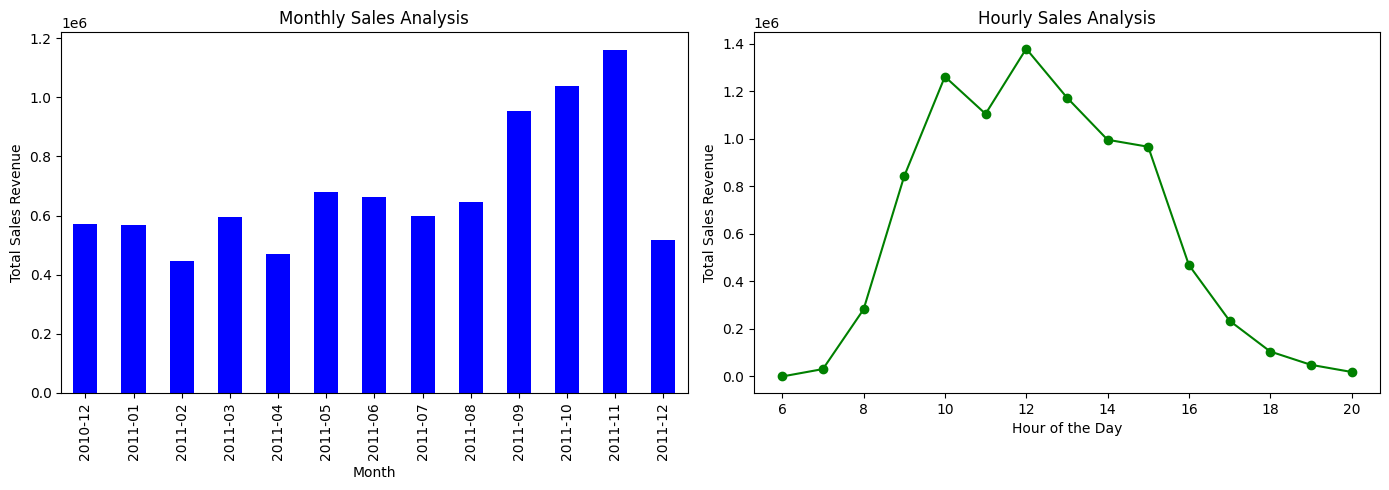

In [80]:
plt.figure(figsize=(14,5))

plt.subplot(1,2,1)
monthly_sales.plot(kind='bar',color='blue')
plt.title('Monthly Sales Analysis')
plt.xlabel('Month')
plt.ylabel('Total Sales Revenue')

plt.subplot(1,2,2)
hourly_sales.plot(kind='line',color='green',marker='o')
plt.title('Hourly Sales Analysis')
plt.xlabel('Hour of the Day')
plt.ylabel('Total Sales Revenue')

plt.tight_layout()
plt.show()


In [52]:
q1=rfm.quantile(0.05)
q3 = rfm.quantile(0.95)
iqr = q3-q1
rfm_clean = rfm[~((rfm<(q1-1.5*iqr))|(rfm>(q3+1.5*iqr)))]

In [61]:
rfm_clean = rfm_clean.replace([np.inf, -np.inf], np.nan)
rfm_clean = rfm_clean.dropna()


In [62]:
from sklearn.preprocessing import StandardScaler

In [63]:
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_clean)
rfm_data = pd.DataFrame(rfm_scaled,columns=rfm_clean.columns,index=rfm_clean.index)

In [64]:
rfm_data

,Recency,Frequency,Monetary
CustomerID,,,
12347.0,-0.917492,1.046278,1.641941
12348.0,-0.188859,-0.458238,0.260251
12349.0,-0.747810,-0.039763,0.238426
12350.0,2.156739,-0.597730,-0.544121
12352.0,-0.578128,0.079801,0.649998
...,...,...,...
18280.0,1.837338,-0.667476,-0.628690
18281.0,0.869155,-0.697367,-0.683556
18282.0,-0.857604,-0.647548,-0.630093


In [65]:
from sklearn.cluster import KMeans

In [66]:
kmeans = KMeans(n_clusters=5,max_iter=50,random_state=42)
kmeans.fit(rfm_data)

KMeans(max_iter=50, n_clusters=5, random_state=42)

In [81]:
cluster_names = {
    0: 'High Frequency Regulars',
    1: 'New / Low-Value Buyers',
    2: 'At-Risk / Lost Customers',
    3: 'VIP / High Value Customers',
    4: 'Potential Loyalists'
}

In [71]:
rfm_clean['cluster']=kmeans.labels_

In [82]:
rfm_clean['Customer_segment'] = rfm_clean['cluster'].map(cluster_names)

In [72]:
import joblib
joblib.dump(kmeans,'customer_segmentation_model.pkl')
print("\n[SUCCESS] Model saved as 'customer_segmentation_model.pkl'")


[SUCCESS] Model saved as 'customer_segmentation_model.pkl'


In [84]:
analysis = rfm_clean.groupby('cluster').agg({
    'Recency':'mean',
    'Frequency':'mean',
    'Monetary':'mean',
    'cluster':'count'
}).rename(columns={'cluster':'customer_count'}).sort_values(by='Monetary',ascending=False)

In [86]:
print("\n--- Final Customer Segment Profiling ---")
print(analysis)


--- Final Customer Segment Profiling ---
            Recency   Frequency     Monetary  customer_count
cluster                                                     
3         21.595745  297.170213  9750.271809              94
0         21.366492  389.392670  4027.382984             191
4         32.494382  142.872659  2613.396256             801
1         51.506030   39.478200   659.791138            2156
2        252.531957   25.604720   429.778328            1017


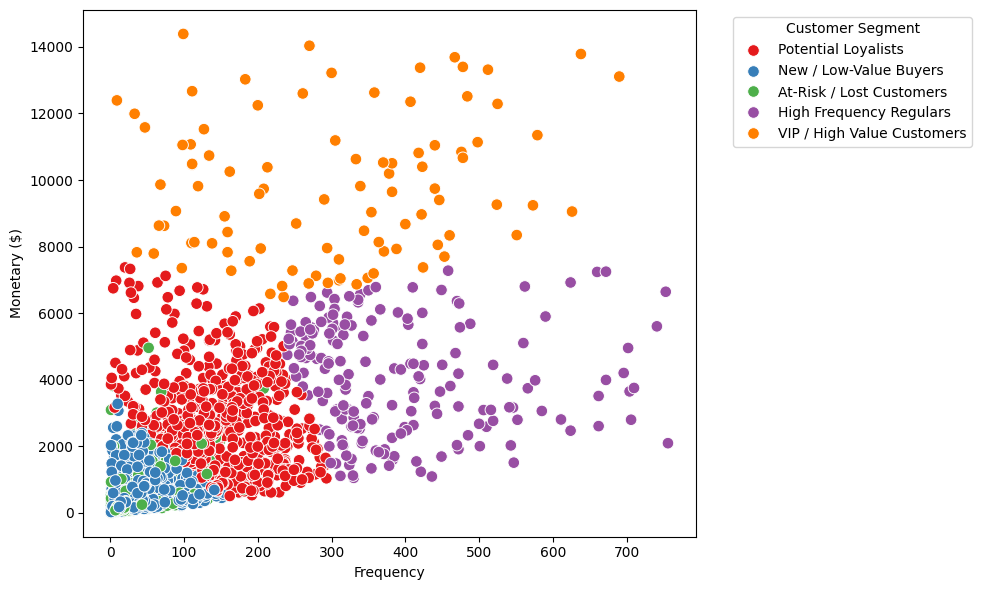

In [88]:
plt.figure(figsize=(10,6))
sns.scatterplot(x='Frequency',y='Monetary',hue='Customer_segment',data=rfm_clean,palette='Set1',s=70)
plt.xlabel('Frequency')
plt.ylabel('Monetary ($)')
plt.legend(title='Customer Segment',bbox_to_anchor=(1.05,1),loc='upper left')
plt.savefig('customer_segments.png')
plt.tight_layout()
plt.show()